# LeukoGuard — Member 1, Parts A & B: Dataset Understanding, EDA and Fixed Cleaning

**Task:** leukemia vs. healthy control (HC) from routine CBC (LeukoAlert public release, `leuk_vs_HC` folder).

**Notebook flow**
1. **A1–A6 Data quality on the raw files**: load, structure, statistics, class balance, missing values (explicit and *disguised*), duplicates, invalid values.
2. **B Fixed cleaning**: deterministic rules derived from A1–A6, applied with `src/leuko_common.py` (the same code every team member imports). Cleaned data and rule log are saved.
3. **A7–A11 Exploratory analysis on the cleaned development set**: distributions, box plots, correlations, leukemia vs. healthy comparison, between-hospital shift.
4. **Summary**: findings and what they mean for modelling.

> **Leakage guard.** Nothing in this notebook learns from data: no imputation, scaling, outlier capping or resampling.
> Those are fitted inside the model pipeline on training folds only. Feature-level EDA (A7–A11) uses **only the development (training) files**,
> so the validation and test hospitals are not inspected before modelling. Data-quality checks (A1–A6) cover all files because the cleaning rules must work on all of them.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
from leuko_common import (RAW_TO_SHORT, DROPPED_BLAST_FLAGS, FEATURES, FEATURE_GROUPS, KEY_FEATURES,
                          CLEANING_RULES, load_raw, clean_frame, file_meta, SEED)

RAW_DIR = ROOT / "data" / "raw"
CLEAN_DIR = ROOT / "data" / "cleaned"; CLEAN_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = ROOT / "reports" / "tables"; TAB_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_HC, C_LK = "#2a78d6", "#eb6834"          # healthy = blue, leukemia = orange (used everywhere)
PAL = {0: C_HC, 1: C_LK}; LAB = {0: "Healthy", 1: "Leukemia"}

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

## A1. Load and inspect the raw dataset
The public release contains 11 CSV files. Each file is one **site (hospital)** within one **split**:

| Split | Files | Role in our study |
|---|---|---|
| `train_site_A/B/C` | 3 | **Development set**: 5-fold CV, tuning, threshold selection |
| `valid_site_A/B/C` | 3 | Internal validation (same hospitals as training, new patients) |
| `valid_site_D/E/F/G` | 4 | **External validation: hospitals never seen in training** (RQ1 held-out hospital) |
| `test_site_true_world` | 1 | Real-world test cohort |

In [2]:
raw = load_raw(RAW_DIR)
raw_cols = [c for c in raw.columns if c not in ("source_file", "split", "site", "cohort")]
print(f"Total records: {len(raw):,}   |   columns per file: {len(raw_cols)} (sample_id + {len(raw_cols)-2} features + label)")
file_summary = (raw.groupby("source_file", observed=True)
                .agg(split=("split", "first"), site=("site", "first"), cohort=("cohort", "first"),
                     rows=("sample_id", "size"), first_id=("sample_id", "first"), last_id=("sample_id", "last"))
                .reset_index())
file_summary

Total records: 446,663   |   columns per file: 76 (sample_id + 74 features + label)


,source_file,split,site,cohort,rows,first_id,last_id
0,test_site_true_world,test,RW,real_world_test,58481,patient_388183,patient_446663
1,train_site_A,train,A,development,11016,patient_000001,patient_011016
2,train_site_B,train,B,development,4215,patient_011017,patient_015231
3,train_site_C,train,C,development,11691,patient_015232,patient_026922
4,valid_site_A,valid,A,internal_validation,59986,patient_026923,patient_086908
5,valid_site_B,valid,B,internal_validation,51228,patient_086909,patient_138136
6,valid_site_C,valid,C,internal_validation,100398,patient_138137,patient_238534
7,valid_site_D,valid,D,external_validation,30166,patient_238535,patient_268700
8,valid_site_E,valid,E,external_validation,94320,patient_268701,patient_363020
9,valid_site_F,valid,F,external_validation,20179,patient_363021,patient_383199


In [3]:
# Do all files share exactly the same header?
headers = {f.stem: tuple(pd.read_csv(f, nrows=0).columns) for f in sorted(RAW_DIR.glob("*.csv"))}
print("Identical header in all 11 files:", len(set(headers.values())) == 1)
feat_raw = [c for c in raw_cols if c not in ("sample_id", "leukemia_label")]
print(f"Raw feature columns: {len(feat_raw)}")
print("Data types:", raw[feat_raw].dtypes.value_counts().to_dict(), "| label:", raw["leukemia_label"].dtype,
      "| label values:", raw["leukemia_label"].unique().tolist())
print("\nColumns in the public files but NOT in the paper's 72-feature list:", list(DROPPED_BLAST_FLAGS))
print("Paper feature missing from the public files: MO-WZ")
print("Usable features after mapping:", len(FEATURES))
grp = pd.DataFrame([(g, len(v), ", ".join(v)) for g, v in FEATURE_GROUPS.items()], columns=["group", "n", "features"])
grp

Identical header in all 11 files: True
Raw feature columns: 74
Data types: {dtype('float64'): 74} | label: str | label values: ['healthy', 'leukemia']

Columns in the public files but NOT in the paper's 72-feature list: ['Q-Flag(Blasts/Abn Lympho?)', 'Q-Flag(Blasts?)', 'Q-Flag(Abn Lympho?)']
Paper feature missing from the public files: MO-WZ
Usable features after mapping: 71


,group,n,features
0,Q-flags,8,"Left Shift, Atypical Lympho, RBC Agglutination, Turbidity/HGB Interf, Iron Deficiency, HGB Defect, Fragments, PLT Clumps"
1,WBC counts,8,"WBC, NEUT#, LYMPH#, MONO#, EO#, BASO#, IG#, NRBC#"
2,Cell percentages,7,"NEUT%, LYMPH%, MONO%, EO%, BASO%, IG%, NRBC%"
3,Red cells,10,"RBC, HGB, HCT, MCV, MCH, MCHC, RDW-SD, RDW-CV, MicroR, MacroR"
4,Platelets,6,"PLT, PLT-F, PDW, MPV, P-LCR, PCT"
5,Extended WBC,15,"TNC, WBC-N, TNC-N, BA-N#, BA-N%, WBC-D, TNC-D, NEUT#&, NEUT%&, LYMPH#&, LYMPH%&, HFLC#, HFLC%, BA-D#, BA-D%"
6,Cell-population,17,"NE-SSC, NE-SFL, NE-FSC, LY-X, LY-Y, LY-Z, MO-X, MO-Y, MO-Z, NE-WX, NE-WY, NE-WZ, LY-WX, LY-WY, LY-WZ, MO-WX, MO-WY"


## A2. Basic statistics (raw development set)
Summary statistics on the three training files, *before* cleaning. Things to look for: impossible minima (zeros), extreme maxima, and HCT having two scales.

In [4]:
dev_raw = raw[raw["split"] == "train"].rename(columns={**RAW_TO_SHORT, **DROPPED_BLAST_FLAGS})
desc = dev_raw[FEATURES].describe(percentiles=[.01, .5, .99]).T
desc["zeros_%"] = (dev_raw[FEATURES] == 0).mean().mul(100).round(2)
desc.round(3).to_csv(TAB_DIR / "A2_raw_dev_descriptives.csv")
desc.loc[KEY_FEATURES + ["MCHC", "PDW", "NE-SSC"]].round(2)

,count,mean,std,min,1%,50%,99%,max,zeros_%
WBC,26922.0,7.75,14.47,0.00,0.04,6.01,43.15,726.67,0.06
NEUT#,26922.0,5.27,9.24,0.00,0.00,3.86,24.76,604.08,2.41
LYMPH#,26922.0,1.50,6.50,0.00,0.00,0.98,9.63,670.15,2.08
MONO#,26922.0,0.88,4.93,0.00,0.00,0.42,8.61,219.20,5.03
NEUT%,26922.0,62.48,24.82,0.00,0.00,67.90,97.10,100.00,2.41
LYMPH%,26922.0,25.07,21.55,0.00,0.00,19.40,94.50,100.00,2.08
MONO%,26922.0,9.08,9.90,0.00,0.00,6.90,55.50,100.00,5.03
HGB,26922.0,103.02,26.67,27.00,53.00,103.00,162.00,208.00,0.00
RBC,26922.0,3.42,0.93,0.56,1.66,3.44,5.48,7.48,0.00
HCT,26922.0,12.78,15.87,0.09,0.18,0.40,45.30,59.80,0.00


## A3. Class distribution
Leukemia prevalence per file and cohort.

In [5]:
raw["y"] = (raw["leukemia_label"].str.lower() == "leukemia").astype(int)
cls = (raw.groupby(["cohort", "source_file"], observed=True)["y"]
       .agg(n="size", leukemia="sum").assign(healthy=lambda d: d.n - d.leukemia,
                                               prevalence_pct=lambda d: (100 * d.leukemia / d.n).round(2),
                                               imbalance_ratio=lambda d: (d.healthy / d.leukemia).round(1)))
cls.to_csv(TAB_DIR / "A3_class_distribution.csv")
print(f"Overall: {raw.y.sum():,} leukemia / {len(raw):,} records = {100*raw.y.mean():.2f}%")
cls

Overall: 24,871 leukemia / 446,663 records = 5.57%


n  leukemia  healthy  prevalence_pct  imbalance_ratio
cohort              source_file                                                                     
development         train_site_A           11016      3672     7344           33.33              2.0
                    train_site_B            4215      1405     2810           33.33              2.0
                    train_site_C           11691      3897     7794           33.33              2.0
external_validation valid_site_D           30166      1324    28842            4.39             21.8
                    valid_site_E           94320      2546    91774            2.70             36.0
                    valid_site_F           20179       989    19190            4.90             19.4
                    valid_site_G            4983       930     4053           18.66              4.4
internal_validation valid_site_A           59986      2732    57254            4.55             21.0
                    valid_site_B           51228       933    50295            1.82             53.9
                    valid_site_C          100398      4153    96245            4.14             23.2
real_world_test     test_site_true_world   58481      2290    56191            3.92             24.5

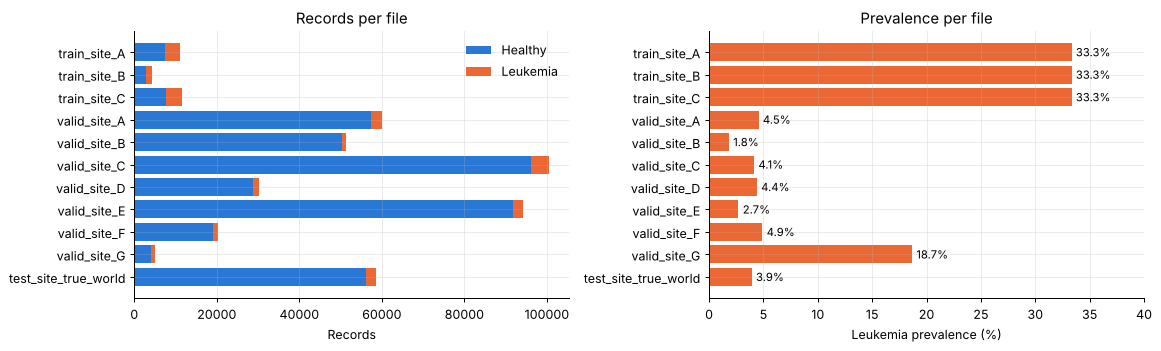

In [6]:
order = ["train_site_A", "train_site_B", "train_site_C", "valid_site_A", "valid_site_B", "valid_site_C",
         "valid_site_D", "valid_site_E", "valid_site_F", "valid_site_G", "test_site_true_world"]
c2 = cls.reset_index().set_index("source_file").loc[order]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(order[::-1], c2["healthy"][::-1], color=C_HC, label="Healthy")
ax[0].barh(order[::-1], c2["leukemia"][::-1], left=c2["healthy"][::-1], color=C_LK, label="Leukemia")
ax[0].set_xlabel("Records"); ax[0].set_title("Records per file"); ax[0].legend(frameon=False)
ax[1].barh(order[::-1], c2["prevalence_pct"][::-1], color=C_LK)
for i, v in enumerate(c2["prevalence_pct"][::-1]):
    ax[1].text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
ax[1].set_xlabel("Leukemia prevalence (%)"); ax[1].set_title("Prevalence per file"); ax[1].set_xlim(0, 40)
plt.tight_layout(); savefig("A3_class_distribution"); plt.show()

**Reading.** The training files are exactly **1 leukemia : 2 healthy (33.3%)** at every site, so the released training set was already **down-sampled**.
Validation and test cohorts have the natural prevalence of **1.8–5%**, plus 18.6% at site G.

Implications:
* In the development set the imbalance is mild (1:2). Class weighting or SMOTE is applied **inside training folds only**.
* Precision and PR-AUC depend on prevalence, so values measured at 33% will be **much lower** on the 2–5% hospitals. Recall and ROC-AUC transfer more directly. Every report states the prevalence next to precision and PR-AUC.
* A decision threshold picked at 33% prevalence still gives the same recall at another prevalence (recall depends only on positives), but precision will drop. This is acceptable for a recall-first screening tool.

## A4. Missing values
### A4.1 Explicit missing values

In [7]:
print("Explicit NaN cells in the raw data:", int(raw[feat_raw].isna().sum().sum()))

Explicit NaN cells in the raw data: 0


There are no empty cells, but that does not mean nothing is missing. Records in the first file contain values like `104.2533936651584`. A haematology analyser
never reports 13 decimals, so these are **gaps that were filled with a mean before release**. To find them systematically:
a value is a fill-in if it is **not on the instrument's precision grid** (instruments report ≤ 3 decimals, so any value with significant digits beyond the 4th decimal).

### A4.2 Disguised missing values (pre-filled means)

In [8]:
def off_grid(s):
    v = s.to_numpy(float); return np.abs(v * 1e4 - np.round(v * 1e4)) > 1e-3

rows = []
for f, g in raw.groupby("source_file", observed=True):
    for c in feat_raw:
        m = off_grid(g[c])
        if m.any():
            u = np.unique(g.loc[m, c])
            rows.append({"file": f, "column": c, "n_filled": int(m.sum()), "pct_filled": 100 * m.mean(),
                         "n_distinct_fill_values": len(u), "fill_value": u[0]})
fills = pd.DataFrame(rows)
fills.to_csv(TAB_DIR / "A4_disguised_missing_by_file.csv", index=False)
print("Distinct fill values per (file, column):", fills["n_distinct_fill_values"].value_counts().to_dict(),
      " -> always exactly ONE value per file-column: a per-file mean imputation.")
blast = fills.column.isin(DROPPED_BLAST_FLAGS)
print(f"Filled cells: {fills.n_filled.sum():,} in total = {fills[blast].n_filled.sum():,} in the 3 blast flags (dropped, R2) "
      f"+ {fills[~blast].n_filled.sum():,} in the 71 usable features (restored to NaN, R3)")
print("\nSame column, different fill value in every file (MPV):")
display(fills[fills.column == "MPV(fL)"][["file", "fill_value", "pct_filled"]].round(3))

Distinct fill values per (file, column): {1: 323}  -> always exactly ONE value per file-column: a per-file mean imputation.
Filled cells: 665,361 in total = 558,990 in the 3 blast flags (dropped, R2) + 106,371 in the 71 usable features (restored to NaN, R3)

Same column, different fill value in every file (MPV):


,file,fill_value,pct_filled
13,test_site_true_world,10.681,5.147
44,train_site_A,10.835,14.225
63,train_site_B,10.330,15.326
104,train_site_C,10.713,11.898
123,valid_site_A,10.751,5.203
152,valid_site_B,10.180,8.835
191,valid_site_D,10.072,8.390
226,valid_site_E,10.567,4.532
251,valid_site_F,10.295,3.816
271,valid_site_G,10.977,8.308


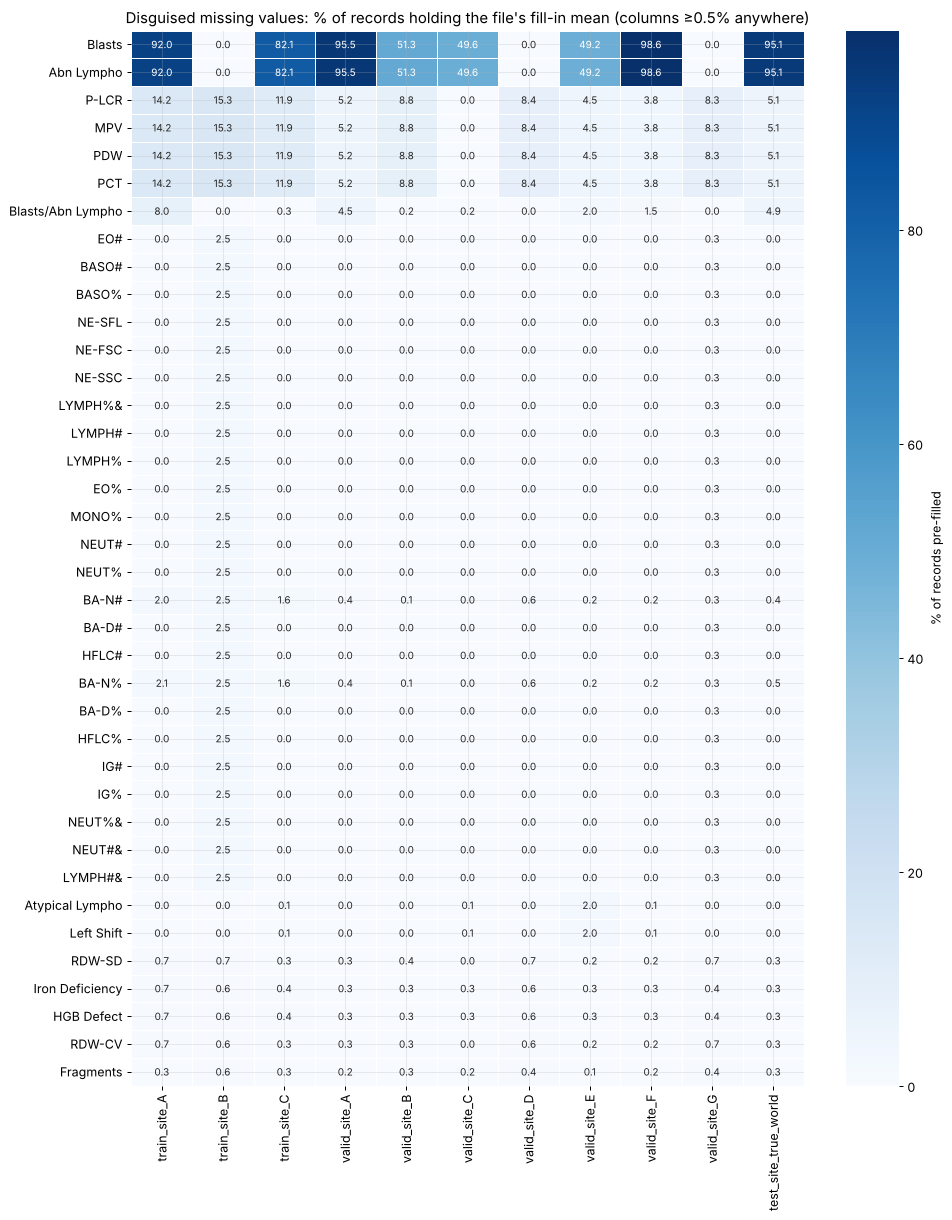

In [9]:
heat = fills.pivot(index="column", columns="file", values="pct_filled").reindex(columns=order).fillna(0)
heat = heat.loc[heat.max(axis=1).sort_values(ascending=False).index]
heat.index = [RAW_TO_SHORT.get(c, DROPPED_BLAST_FLAGS.get(c, c)) for c in heat.index]
top = heat[heat.max(axis=1) >= 0.5]
fig, ax = plt.subplots(figsize=(11, 0.32 * len(top) + 1.5))
sns.heatmap(top, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of records pre-filled"}, ax=ax,
            annot_kws={"fontsize": 8}, linewidths=0.5, linecolor="white")
ax.set_title("Disguised missing values: % of records holding the file's fill-in mean (columns ≥0.5% anywhere)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); savefig("A4_disguised_missing_heatmap"); plt.show()

### A4.3 Zero-coded missing values
Some sites code "not measured" as **0** instead of a mean. A zero is impossible for several CBC parameters in a living patient.

In [10]:
R = raw.rename(columns={**RAW_TO_SHORT, **DROPPED_BLAST_FLAGS})
diff_sum = R[["NEUT%", "LYMPH%", "MONO%", "EO%", "BASO%"]].sum(axis=1)
checks = {
    "RBC panel = 0 (RBC/HGB/HCT/MCV)": (R[["RBC", "HGB", "HCT", "MCV"]] == 0).any(axis=1),
    "MPV = 0 (platelet indices not computed)": R["MPV"] == 0,
    "Differential % sum = 0 (no differential)": diff_sum == 0,
    "NE-SSC = 0 (cell-population params absent)": R["NE-SSC"] == 0,
    "LY-X = 0": R["LY-X"] == 0,
    "MO-X = 0": R["MO-X"] == 0,
}
zc = pd.DataFrame({k: {"records": int(m.sum()), "pct": round(100 * m.mean(), 2),
                       "leukemia_rate_%": round(100 * R.loc[m, "y"].mean(), 1) if m.any() else np.nan}
                   for k, m in checks.items()}).T
print(f"Baseline leukemia rate: {100*R.y.mean():.1f}%")
zc

Baseline leukemia rate: 5.6%


,records,pct,leukemia_rate_%
RBC panel = 0 (RBC/HGB/HCT/MCV),15.0,0.00,0.0
MPV = 0 (platelet indices not computed),5390.0,1.21,16.6
Differential % sum = 0 (no differential),3856.0,0.86,31.4
NE-SSC = 0 (cell-population params absent),3947.0,0.88,32.9
LY-X = 0,2166.0,0.48,8.6
MO-X = 0,2758.0,0.62,23.0


In [11]:
# Zero-coded missingness by file (shows it is a SITE practice, not random)
zc_file = pd.DataFrame({k: m.groupby(R["source_file"]).mean().mul(100) for k, m in checks.items()}).loc[order].round(2)
zc_file

,RBC panel = 0 (RBC/HGB/HCT/MCV),MPV = 0 (platelet indices not computed),Differential % sum = 0 (no differential),NE-SSC = 0 (cell-population params absent),LY-X = 0,MO-X = 0
source_file,,,,,,
train_site_A,0.00,0.01,2.09,2.33,0.15,1.30
train_site_B,0.00,0.00,0.00,0.02,0.02,0.93
train_site_C,0.00,0.04,1.77,1.86,0.15,0.67
valid_site_A,0.00,0.00,0.42,0.46,0.03,0.16
valid_site_B,0.00,0.00,0.15,0.16,0.03,0.06
valid_site_C,0.01,5.34,0.47,0.47,0.12,0.20
valid_site_D,0.01,0.00,0.58,0.58,0.04,0.20
valid_site_E,0.00,0.02,2.22,2.23,2.02,2.07
valid_site_F,0.00,0.01,0.33,0.37,0.09,0.22


In [12]:
# When the differential is absent, which columns are zero? (defines the block that R7 blanks out)
blk = (R.loc[diff_sum == 0, FEATURES] == 0).mean().sort_values(ascending=False)
print("Columns that are ALWAYS 0 when the differential is absent:")
print(", ".join(blk[blk == 1].index))
print("\nWBC is still measured in those records: median WBC =", R.loc[diff_sum == 0, "WBC"].median(),
      "| WBC>0 in", f"{100*(R.loc[diff_sum==0,'WBC']>0).mean():.1f}%")

Columns that are ALWAYS 0 when the differential is absent:
EO%, BASO%, IG#, NEUT%, BASO#, LYMPH%, MONO%, NEUT%&, LYMPH#&, LYMPH%&, HFLC#, HFLC%, BA-D#, BA-D%, IG%, EO#, MONO#, LYMPH#, NEUT#, NEUT#&

WBC is still measured in those records: median WBC = 1.12 | WBC>0 in 96.6%


**Reading (A4).**
* The raw data has **no explicit NaN**, but **~105k cells are pre-filled means**. Each file has its own fill value, so the same missing MPV is `12.49` at train-A, `11.43` at train-B and `12.27` at train-C.
  If left in place, (i) the models would see artificial spikes, (ii) the fill value itself would identify the hospital, and (iii) a mean computed over a whole file (including test patients) would leak into training. **They must be turned back into NaN** (rule R3) and re-imputed inside training folds.
* **Blast flags** (`Blasts?`, `Abn Lympho?`) are pre-filled in 50–95% of records, and at train-B and valid-D/G every record holds the same constant (never measured). Unusable, so they are dropped (R2).
* **Zero-coded gaps** come in blocks: the platelet-index block (MPV=0), the differential block (all % = 0) and the cell-population parameters. The pattern differs by site; valid-E has many CBC-only orders.
* Missingness is **informative**. A missing differential has a 31% leukemia rate against a 5.6% baseline: the analyser often cannot classify abnormal cells. Missing platelet indices go with very low platelets.
  For modelling this means imputation **plus missing-indicator columns** inside the pipeline. We also need to check that a model doesn't just learn site-specific recording habits.

## A5. Duplicate records and patient identity

In [13]:
print("sample_id unique across all files:", raw["sample_id"].is_unique)
dup_any = raw.duplicated(feat_raw, keep=False)
dup_lab = raw.duplicated(feat_raw + ["leukemia_label"], keep="first")
print(f"Records whose 74 features exactly match another record: {dup_any.sum()}")
print(f"Exact duplicates (features + label) that would be removed: {dup_lab.sum()}")
d = raw[dup_any]
print("Files involved:", d.groupby("source_file", observed=True).size().to_dict())
print("Do any duplicate groups span more than one file (cross-split leakage)?",
      bool((d.groupby(feat_raw)["source_file"].nunique() > 1).any()))
print("Duplicate groups with CONFLICTING labels:", int((d.groupby(feat_raw)["leukemia_label"].nunique() > 1).sum()))

sample_id unique across all files: True
Records whose 74 features exactly match another record: 31
Exact duplicates (features + label) that would be removed: 20
Files involved: {'valid_site_D': 18, 'valid_site_G': 13}
Do any duplicate groups span more than one file (cross-split leakage)? False
Duplicate groups with CONFLICTING labels: 1


**Reading (A5).** Only 31 records (in valid-D and valid-G) exactly duplicate another record, and none cross a split, so no train/test leakage comes from copies.
The valid-G "duplicates" are records that were **empty and entirely mean-filled** (85% of their values are fill-ins), which is why they are identical, healthy and leukemia alike.
That conflicting-label group is dropped entirely (R10); valid-D has 9 true repeat records.

**Patient identity:** `sample_id` is a running record number (`patient_000001` …), unique per row. The original study had multiple CBCs per person (446,558 records from 203,284 people),
but the public release has **no patient key**. So the proposal's "keep each patient's records in the same split" can only be honoured at the level the publishers did, which is separate files per split and hospital.
Within the development files, repeat CBCs of the same person could fall into different CV folds. CV scores may therefore be slightly optimistic, which is one more reason to judge generalisation on the **external hospitals**. This is a stated limitation.

## A6. Invalid / impossible values
### A6.1 HCT recorded in two different units

,min,50%,max,unit_inferred
source_file,,,,
train_site_A,5.500,31.30000,59.800,percent
train_site_B,0.126,0.33300,0.605,fraction (L/L)
train_site_C,0.093,0.31600,0.645,fraction (L/L)
valid_site_A,10.800,35.50000,66.000,percent
valid_site_B,0.004,0.36600,0.805,fraction (L/L)
valid_site_C,0.000,0.34600,0.823,fraction (L/L)
valid_site_D,0.000,34.00000,63.700,percent
valid_site_E,0.000,38.50000,77.900,percent
valid_site_F,8.800,35.90000,76.600,percent


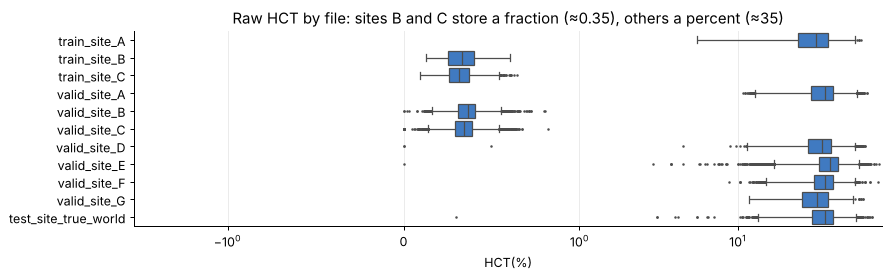

In [14]:
hct = raw[["source_file", "HCT(%)"]].copy()
hct_tab = hct.groupby("source_file", observed=True)["HCT(%)"].describe()[["min", "50%", "max"]].loc[order]
hct_tab["unit_inferred"] = np.where(hct_tab["50%"] < 1, "fraction (L/L)", "percent")
display(hct_tab)
fig, ax = plt.subplots(figsize=(10, 3.2))
sns.boxplot(data=hct[~off_grid(hct["HCT(%)"])], y="source_file", x="HCT(%)", order=order, color=C_HC, fliersize=1, ax=ax)
ax.set_xscale("symlog", linthresh=1); ax.set_title("Raw HCT by file: sites B and C store a fraction (≈0.35), others a percent (≈35)")
ax.set_ylabel(""); plt.tight_layout(); savefig("A6_HCT_units"); plt.show()

### A6.2 Physiologically impossible values

In [15]:
imp = {
    "HGB = 0 g/L": (R["HGB"] == 0),
    "RBC = 0": (R["RBC"] == 0),
    "MCV = 0 fL": (R["MCV"] == 0),
    "MCHC > 500 g/L": (R["MCHC"] > 500),
    "MCH > 60 pg": (R["MCH"] > 60),
    "Any negative value": (R[FEATURES] < 0).any(axis=1),
    "Any % > 100": (R[["NEUT%", "LYMPH%", "MONO%", "EO%", "BASO%", "IG%", "NEUT%&", "LYMPH%&"]] > 100).any(axis=1),
    "WBC = 0 (kept: below-detection reading)": (R["WBC"] == 0),
    "PLT = 0 (kept: below-detection reading)": (R["PLT"] == 0),
}
imp_tab = pd.DataFrame({k: {"records": int(m.sum()), "leukemia_rate_%": round(100 * R.loc[m, "y"].mean(), 1) if m.any() else np.nan}
                        for k, m in imp.items()}).T
display(imp_tab)
print("Examples of MCHC > 500 g/L (RBC count corrupted, often with RBC-agglutination flag):")
R.loc[R["MCHC"] > 500, ["source_file", "y", "RBC", "HGB", "HCT", "MCV", "MCH", "MCHC", "RBC Agglutination"]].head(6)

,records,leukemia_rate_%
HGB = 0 g/L,15.0,0.0
RBC = 0,15.0,0.0
MCV = 0 fL,12.0,0.0
MCHC > 500 g/L,139.0,14.4
MCH > 60 pg,83.0,16.9
Any negative value,0.0,NaN
Any % > 100,0.0,NaN
WBC = 0 (kept: below-detection reading),133.0,47.4
PLT = 0 (kept: below-detection reading),54.0,27.8


Examples of MCHC > 500 g/L (RBC count corrupted, often with RBC-agglutination flag):


,source_file,y,RBC,HGB,HCT,MCV,MCH,MCHC,RBC Agglutination
5619,test_site_true_world,0,2.47,131.0,22.9,92.7,53.0,572.0,130.0
6974,test_site_true_world,0,2.44,116.0,22.1,90.6,47.5,525.0,110.0
11801,test_site_true_world,0,1.81,94.0,17.2,95.0,51.9,547.0,120.0
14013,test_site_true_world,0,2.54,130.0,23.3,91.7,51.2,558.0,120.0
14016,test_site_true_world,0,2.67,131.0,24.2,90.6,49.1,541.0,120.0
14989,test_site_true_world,0,0.47,77.0,5.5,117.0,163.8,1400.0,0.0


**Reading (A6).**
* **HCT**: sites B and C (both training and validation files) record HCT as a fraction. Left unfixed, HCT would separate hospitals rather than patients. It is converted to % (R4).
* **Zero RBC/HGB/MCV** (15 records, all healthy) are failed measurements, so they become NaN (R5).
* **MCHC > 500 g/L** (139 records) is physically impossible; it is the classic cold-agglutinin / optical artefact, where the RBC count is falsely low, inflating MCH and MCHC. Both indices become NaN (R9). The record is kept because its other values are valid.
* **WBC = 0 and PLT = 0 are kept.** They are real "below detection" readings. Nearly half of WBC = 0 records are leukemia (marrow failure / post-treatment aplasia), so removing them would delete signal.
* Extreme values such as **WBC up to 727 ×10⁹/L** are hyperleukocytosis, a hallmark of leukemia, not errors. **No outlier removal** is done at this stage. Any capping or transformation is learned in the pipeline.

## B. Fixed (deterministic) cleaning
The rules below are derived from A1–A6. Each one acts on a single record or a single file's recording convention, never on statistics learned from labels or from other splits, so they can be applied to every file before modelling.
**Not done here (fitted inside CV folds instead):** imputation, missing-indicators, scaling, log/outlier transforms, SMOTE/class weights.

In [16]:
rules = pd.DataFrame(CLEANING_RULES, columns=["id", "rule", "rationale"])
rules

,id,rule,rationale
0,R1,Rename columns,Raw headers -> short team names (e.g. 'WBC(10^9/L)' -> 'WBC'). Label 'leukemia'/'healthy' -> y = 1/0.
1,R2,Drop blast-suspicion flags,"Q-Flag(Blasts/Abn Lympho?), Q-Flag(Blasts?), Q-Flag(Abn Lympho?) dropped: not in the paper's 72 features, 50-100% missing/constant at every site, and they are the analyser's own blast message (shortcut to the label)."
2,R3,Disguised missing -> NaN,"In each file, each column contains exactly one value off the instrument's precision grid (e.g. 104.2533936651584). It is that file's column mean used as a fill-in. Every off-grid value is set back to NaN so imputation can be learned inside training folds."
3,R4,HCT unit harmonisation,Files whose median HCT < 1 (sites B and C) store HCT as a fraction (L/L). Multiply by 100 so HCT is in % everywhere.
4,R5,RBC panel zero -> NaN,"RBC, HGB, HCT, MCV, MCH, MCHC, RDW-SD, RDW-CV equal to 0 are impossible in a living patient (failed measurement) -> NaN."
5,R6,Platelet indices not computed -> NaN,"When MPV = 0 the analyser did not compute the platelet-index block; PDW, MPV, P-LCR, PCT are set to NaN for that record."
6,R7,Differential not performed -> NaN,When NEUT%+LYMPH%+MONO%+EO%+BASO% = 0 no differential was reported; the whole differential block (23 columns) is set to NaN. WBC is kept.
7,R8,Cell-population zero -> NaN,NE-/LY-/MO- scattergram positions and widths equal to 0 are 'not measured' (a channel position cannot be 0) -> NaN.
8,R9,Impossible MCHC,MCHC > 500 g/L is physically impossible (agglutination/optical artefact); MCHC and MCH (both derived from the corrupted RBC count) -> NaN.
9,R10,Duplicates,Exact duplicate records (all features + label) within a file: keep the first. Identical features with conflicting labels: drop all copies.


In [17]:
clean, clean_log = clean_frame(raw.drop(columns=["y"]))
summary = clean_log.groupby("rule", sort=False).agg(changes=("n_changed", "sum"), detail=("detail", lambda s: "; ".join(sorted(set(s)))[:120]))
print(f"Raw records: {len(raw):,}  ->  cleaned records: {len(clean):,}  (removed {len(raw)-len(clean)})")
print(f"Columns: {clean.shape[1]} = {len(clean.columns)-len(FEATURES)} meta + {len(FEATURES)} features")
summary

Raw records: 446,663  ->  cleaned records: 446,637  (removed 26)
Columns: 77 = 6 meta + 71 features


,changes,detail
rule,,
R10,22,"11 exact dups, 13 conflicting-label rows; 9 exact dups, 0 conflicting-label rows"
R2,3,columns dropped
R3,105552,cells set to NaN
R4,167532,HCT x100 (fraction -> %)
R5,549,HCT; HGB; MCH; MCHC; MCV; RBC; RDW-CV; RDW-SD
R6,5390,records
R7,3856,records
R8,34046,LY-WX; LY-WY; LY-WZ; LY-X; LY-Y; LY-Z; MO-WX; MO-WY; MO-X; MO-Y; MO-Z; NE-FSC; NE-SFL; NE-SSC; NE-WX; NE-WY; NE-WZ
R9,139,records


In [18]:
# Missingness after cleaning: now explicit and honest
miss = (clean.groupby("cohort", observed=True)[FEATURES].apply(lambda g: g.isna().mean() * 100).T.round(2))
miss["overall"] = clean[FEATURES].isna().mean().mul(100).round(2)
miss = miss.sort_values("overall", ascending=False)
miss.to_csv(TAB_DIR / "B_missing_after_cleaning.csv")
display(miss.head(12))
print("Features with no missing values at all:", int((miss["overall"] == 0).sum()), "of", len(FEATURES))
print("Records with >50% features missing (CBC-only orders):", int((clean[FEATURES].isna().mean(axis=1) > .5).sum()))

cohort,development,external_validation,internal_validation,real_world_test,overall
PCT,13.41,5.34,6.15,5.15,6.18
P-LCR,13.41,5.34,6.15,5.15,6.18
MPV,13.41,5.34,6.15,5.15,6.18
PDW,13.41,5.34,6.15,5.15,6.18
NE-SSC,2.16,1.57,0.39,0.51,0.91
NE-FSC,2.16,1.57,0.39,0.51,0.91
NE-SFL,2.17,1.57,0.40,0.51,0.91
BA-D#,2.01,1.56,0.38,0.49,0.89
HFLC%,2.01,1.56,0.38,0.49,0.89
LYMPH%&,2.01,1.56,0.38,0.49,0.89


Features with no missing values at all: 15 of 71
Records with >50% features missing (CBC-only orders): 2130


In [19]:
# Sanity checks on the cleaned data
assert clean["sample_id"].is_unique
assert not any(off_grid(clean[c].dropna()).any() for c in FEATURES), "fill values remain"
assert (clean.groupby("site", observed=True)["HCT"].median() > 20).all(), "HCT unit not harmonised"
assert (clean[["RBC", "HGB", "HCT", "MCV"]].fillna(1) > 0).all(axis=None)
assert clean["MCHC"].max() <= 500
print("All sanity checks passed.")
print(clean.groupby("site", observed=True)["HCT"].median().round(1).to_dict())

All sanity checks passed.
{'A': 35.0, 'B': 36.4, 'C': 34.3, 'D': 34.0, 'E': 38.5, 'F': 35.9, 'G': 31.7, 'RW': 35.5}


In [20]:
# Save cleaned data + documentation
clean.to_csv(CLEAN_DIR / "leukoalert_cleaned.csv.gz", index=False, compression="gzip")
for name, g in clean.groupby("cohort", observed=True):
    g.to_csv(CLEAN_DIR / f"cleaned_{name}.csv", index=False)
clean_log.to_csv(CLEAN_DIR / "cleaning_log.csv", index=False)
rules.to_csv(CLEAN_DIR / "cleaning_rules.csv", index=False)
print("Saved:", sorted(p.name for p in CLEAN_DIR.iterdir()))

Saved: ['cleaned_development.csv', 'cleaned_external_validation.csv', 'cleaned_internal_validation.csv', 'cleaned_real_world_test.csv', 'cleaning_log.csv', 'cleaning_rules.csv', 'leukoalert_cleaned.csv.gz']


## A7. Distributions (cleaned development set)
From here on, only the **development set** (train A, B, C; n ≈ 26.9k) is used, so the evaluation hospitals stay unseen.

First, why cleaning mattered for EDA: the raw MPV histogram has a tall spike at the fill-in mean. After cleaning, those records are NaN.

Development set: 26,922 records, 8,974 leukemia (33.3%)


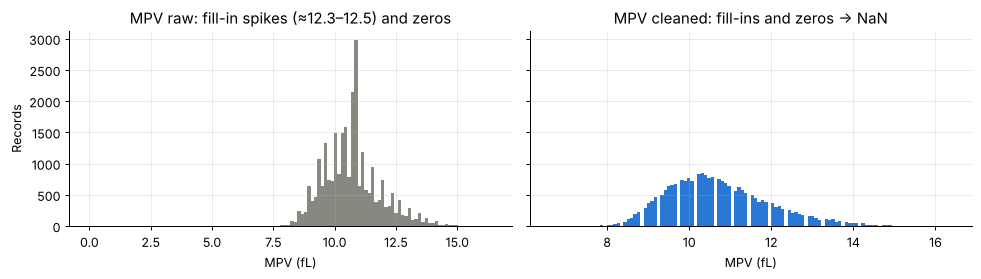

In [21]:
dev = clean[clean["split"] == "train"].reset_index(drop=True)
print(f"Development set: {len(dev):,} records, {dev.y.sum():,} leukemia ({100*dev.y.mean():.1f}%)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
ax[0].hist(dev_raw["MPV"], bins=120, color="#888780"); ax[0].set_title("MPV raw: fill-in spikes (≈12.3–12.5) and zeros")
ax[1].hist(dev["MPV"].dropna(), bins=120, color=C_HC); ax[1].set_title("MPV cleaned: fill-ins and zeros → NaN")
for a in ax: a.set_xlabel("MPV (fL)")
ax[0].set_ylabel("Records"); plt.tight_layout(); savefig("A7_MPV_raw_vs_clean"); plt.show()

Most right-skewed features (skew > 5): HFLC# (145), BA-D# (66), LYMPH#& (63), LYMPH# (62), IG# (45), NRBC# (41), BASO# (40), BA-N# (38), EO# (36), NRBC% (35), NEUT# (25), MONO# (23), WBC-D (21), TNC-D (21), WBC-N (21), WBC (21), TNC-N (21), TNC (21), HFLC% (14), NEUT#& (12), BA-D% (12), BASO% (11), BA-N% (9), EO% (6), MicroR (6), IG% (5)


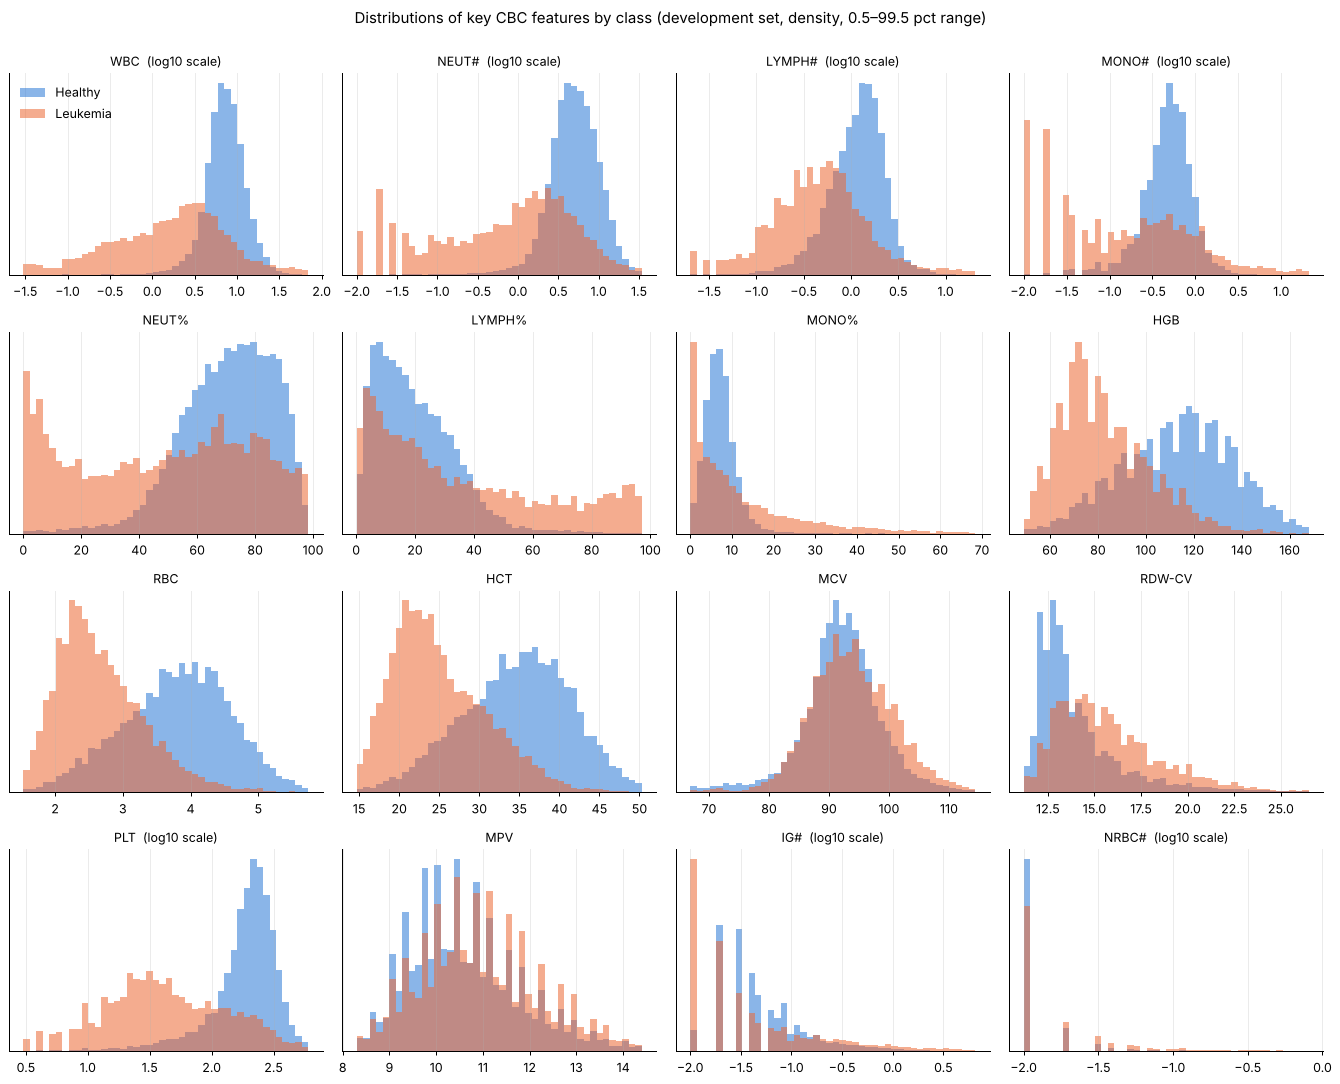

In [22]:
skewness = dev[FEATURES].skew().sort_values(ascending=False)
print("Most right-skewed features (skew > 5):", ", ".join(f"{k} ({v:.0f})" for k, v in skewness[skewness > 5].items()))
LOGX = {"WBC", "NEUT#", "LYMPH#", "MONO#", "EO#", "BASO#", "IG#", "NRBC#", "PLT", "IG%", "NRBC%"}
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
for ax, f in zip(axes.ravel(), KEY_FEATURES):
    s = dev[[f, "y"]].dropna()
    log = f in LOGX
    vals = np.log10(s[f] + 0.01) if log else s[f]
    lo, hi = np.nanpercentile(vals, [0.5, 99.5])
    bins = np.linspace(lo, hi, 45)   # 45 bins: avoids aliasing with the 0.1-unit reporting resolution
    for k in (0, 1):
        ax.hist(vals[s.y == k], bins=bins, density=True, alpha=0.55, color=PAL[k], label=LAB[k])
    ax.set_title(f + ("  (log10 scale)" if log else ""), fontsize=10); ax.set_yticks([])
axes[0, 0].legend(frameon=False)
fig.suptitle("Distributions of key CBC features by class (development set, density, 0.5–99.5 pct range)", y=1.0)
plt.tight_layout(); savefig("A7_histograms_key_features"); plt.show()

**Reading (A7).** Count variables (WBC, the absolute differential counts, PLT, IG#, NRBC#) are **heavily right-skewed** and span several orders of magnitude. On a log scale they look roughly normal,
so **log-transforming counts is advisable for Logistic Regression** (done inside the pipeline; tree models don't need it).
Leukemia records have a **much wider WBC distribution shifted to low values** (median 1.9 vs 7.3 ×10⁹/L in healthy), with a long high tail (hyperleukocytosis). Both leukopenic and leukocytotic presentations occur, and many records are probably from patients under treatment.
Leukemia also shows **lower HGB, RBC, HCT and PLT** (anaemia and thrombocytopenia from marrow failure), a **wider RDW**, and **NEUT%/LYMPH% spread over the whole 0–100 range** (abnormal or unclassified cells). MCV and MPV differ only slightly.
Spikes at the left edge of the log-scaled IG#, NRBC#, MONO# panels are the instrument's 0.01 resolution steps, not data errors.

## A8. Box plots for important CBC features

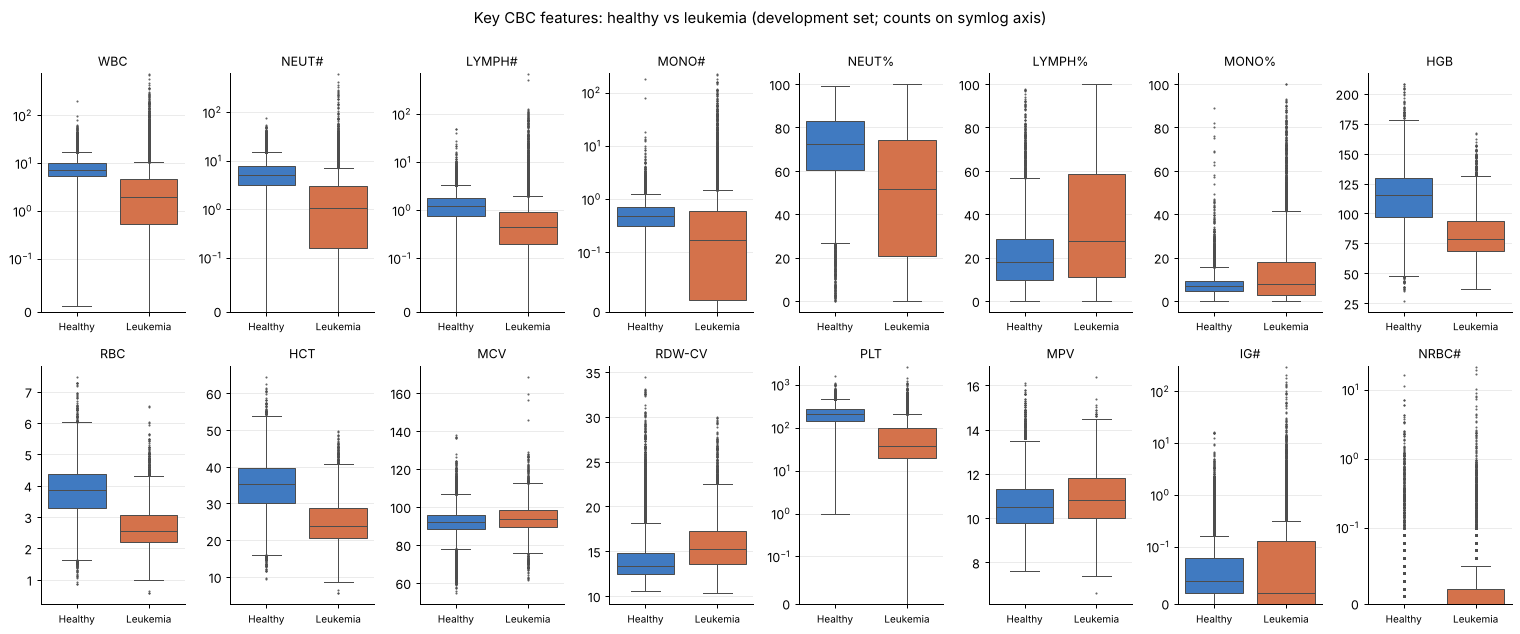

In [23]:
fig, axes = plt.subplots(2, 8, figsize=(17, 7))
for ax, f in zip(axes.ravel(), KEY_FEATURES):
    s = dev[[f, "y"]].dropna().copy(); s["cls"] = s.y.map(LAB)
    sns.boxplot(data=s, x="cls", y=f, hue="cls", palette={"Healthy": C_HC, "Leukemia": C_LK}, order=["Healthy", "Leukemia"],
                fliersize=0.6, linewidth=0.8, ax=ax, legend=False)
    if f in LOGX: ax.set_yscale("symlog", linthresh=0.1); ax.set_ylim(bottom=0)
    ax.set_title(f, fontsize=10); ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Key CBC features: healthy vs leukemia (development set; counts on symlog axis)", y=1.0)
plt.tight_layout(); savefig("A8_boxplots_key_features"); plt.show()

In [24]:
# Outlier census (IQR rule) - descriptive only; NOT used to remove anything
q1, q3 = dev[FEATURES].quantile(.25), dev[FEATURES].quantile(.75); iqr = q3 - q1
out = ((dev[FEATURES] < q1 - 3 * iqr) | (dev[FEATURES] > q3 + 3 * iqr))
out_tab = pd.DataFrame({"extreme_outliers_%": out.mean().mul(100).round(2),
                        "of_which_leukemia_%": [round(100 * dev.loc[out[c], "y"].mean(), 1) if out[c].any() else np.nan for c in FEATURES]})
out_tab = out_tab.loc[KEY_FEATURES].sort_values("extreme_outliers_%", ascending=False)
out_tab

,extreme_outliers_%,of_which_leukemia_%
IG#,8.53,52.6
NRBC#,7.45,65.0
MONO%,4.85,93.3
MONO#,3.06,82.9
LYMPH#,2.06,65.7
WBC,1.88,72.3
NEUT#,1.38,43.9
RDW-CV,0.78,35.1
MCV,0.56,23.3
PLT,0.10,53.8


**Reading (A8).** Extreme outliers (beyond 3×IQR) in WBC, the absolute counts, IG# and NRBC# are **mostly leukemia records**. These "outliers" are the disease signal, which confirms the decision **not** to remove or cap them in fixed cleaning.
For LR, a log transform (and optionally winsorising learned on training folds) limits their leverage without discarding them.

## A9. Correlations between CBC features
Spearman (rank) correlation because the features are skewed.

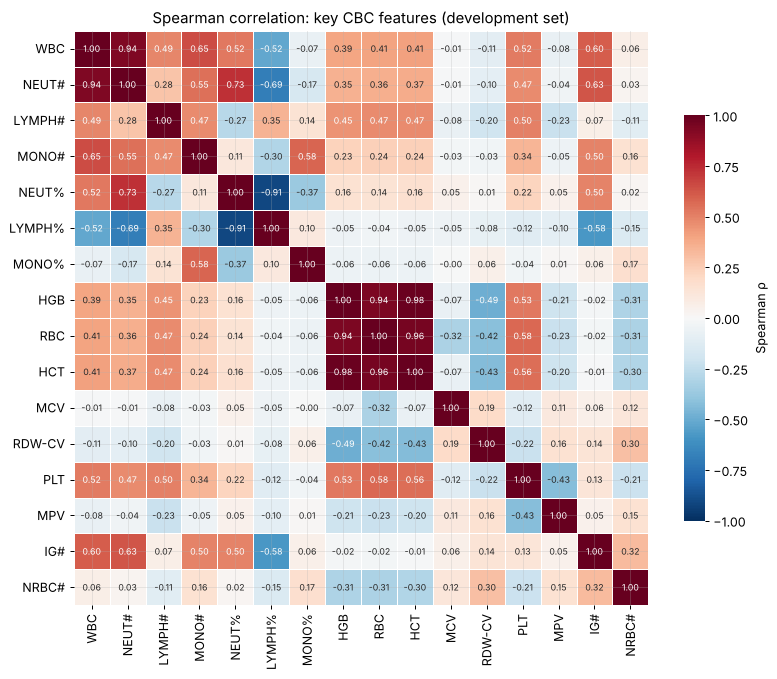

In [25]:
corr = dev[FEATURES].corr(method="spearman")
corr.round(3).to_csv(TAB_DIR / "A9_spearman_correlation_all.csv")
fig, ax = plt.subplots(figsize=(9, 7.5))
kc = dev[KEY_FEATURES].corr(method="spearman")
sns.heatmap(kc, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"fontsize": 7},
            square=True, cbar_kws={"label": "Spearman ρ", "shrink": .7}, ax=ax, linewidths=.4, linecolor="white")
ax.set_title("Spearman correlation: key CBC features (development set)")
plt.tight_layout(); savefig("A9_corr_key_features"); plt.show()

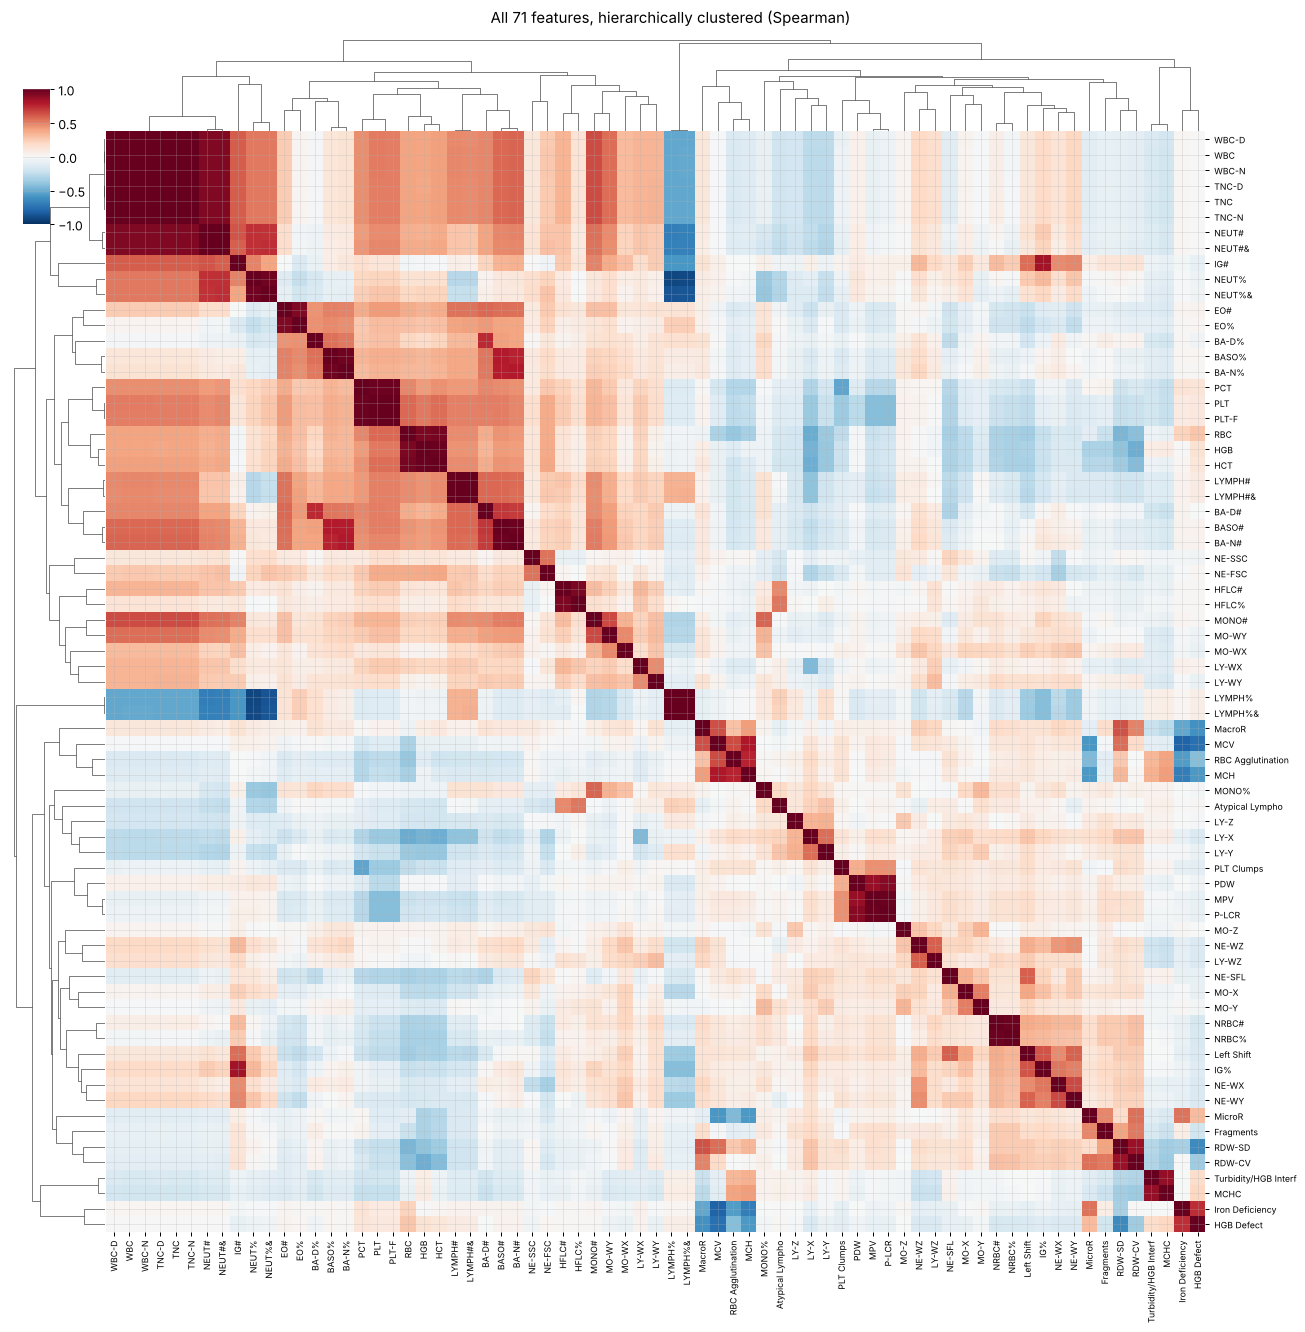

In [26]:
cg = sns.clustermap(corr.fillna(0), cmap="RdBu_r", vmin=-1, vmax=1, center=0, figsize=(15, 15),
                    xticklabels=True, yticklabels=True, cbar_pos=(0.02, 0.85, 0.02, 0.1), dendrogram_ratio=0.08)
cg.ax_heatmap.tick_params(labelsize=7); cg.fig.suptitle("All 71 features, hierarchically clustered (Spearman)", y=1.01)
cg.savefig(FIG_DIR / "A9_corr_all_clustered.png", dpi=110, bbox_inches="tight"); plt.show()

In [27]:
iu = np.triu(np.ones(corr.shape, bool), 1)
pairs = (corr.where(iu).stack().rename("rho").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs"] = pairs.rho.abs()
high = pairs[pairs["abs"] >= 0.95].sort_values("abs", ascending=False).drop(columns="abs")
high.to_csv(TAB_DIR / "A9_highly_correlated_pairs.csv", index=False)
print(f"Feature pairs with |ρ| ≥ 0.95: {len(high)}  (|ρ| ≥ 0.90: {(pairs['abs'] >= .9).sum()})")
high.head(30).round(3)

Feature pairs with |ρ| ≥ 0.95: 28  (|ρ| ≥ 0.90: 46)


,feature_1,feature_2,rho
608,WBC,WBC-N,1.000
2810,TNC,TNC-N,1.000
3169,WBC-D,TNC-D,1.000
607,WBC,TNC,1.000
2881,WBC-N,TNC-N,1.000
2809,TNC,WBC-N,1.000
609,WBC,TNC-N,1.000
1101,PLT,PLT-F,1.000
2179,LYMPH%,LYMPH%&,0.999
1823,LYMPH#,LYMPH#&,0.999


**Reading (A9).** There is strong **redundancy**. WBC ≈ TNC ≈ WBC-N ≈ TNC-N ≈ WBC-D ≈ TNC-D (alternative WBC channels), PLT ≈ PLT-F, BASO ≈ BA-N ≈ BA-D, NEUT ≈ NEUT&, LYMPH ≈ LYMPH&,
and RBC ≈ HGB ≈ HCT. MPV, PDW and P-LCR are near-collinear too.
For **Logistic Regression** this multicollinearity makes individual coefficients and odds ratios unstable and hard to read, so the LR part will use **regularisation (L1/L2/elastic-net)**
and coefficients will be interpreted on a **reduced, de-duplicated feature set**. Tree models are not affected.

## A10. Leukemia vs. non-leukemia: feature-by-feature comparison
For each feature: medians per class, a **Mann-Whitney U** test (non-parametric), **Holm-corrected** p-values and **Cliff's δ** effect size
(δ > 0 means higher in leukemia; |δ| ≥ 0.147 small, ≥ 0.33 medium, ≥ 0.474 large). With n ≈ 27k almost everything is "significant", so the **effect size** is what matters.

In [28]:
rows = []
for f in FEATURES:
    a, b = dev.loc[dev.y == 1, f].dropna(), dev.loc[dev.y == 0, f].dropna()
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    delta = 2 * U / (len(a) * len(b)) - 1
    rows.append({"feature": f, "group": next(g for g, v in FEATURE_GROUPS.items() if f in v),
                 "median_healthy": b.median(), "median_leukemia": a.median(),
                 "missing_%_healthy": 100 * dev.loc[dev.y == 0, f].isna().mean(), "missing_%_leukemia": 100 * dev.loc[dev.y == 1, f].isna().mean(),
                 "cliffs_delta": delta, "p_value": p})
cmp_ = pd.DataFrame(rows)
cmp_["p_holm"] = np.minimum(1, np.maximum.accumulate((len(cmp_) - np.arange(len(cmp_))) * np.sort(cmp_.p_value)))[np.argsort(np.argsort(cmp_.p_value))]
cmp_["effect"] = pd.cut(cmp_.cliffs_delta.abs(), [-1, .147, .33, .474, 1.01], labels=["negligible", "small", "medium", "large"])
cmp_ = cmp_.sort_values("cliffs_delta", key=np.abs, ascending=False).reset_index(drop=True)
cmp_.to_csv(TAB_DIR / "A10_class_comparison_all_features.csv", index=False)
print("Effect-size classes:", cmp_.effect.value_counts().to_dict())
cmp_.head(25).round({"median_healthy": 2, "median_leukemia": 2, "missing_%_healthy": 1, "missing_%_leukemia": 1, "cliffs_delta": 3}).assign(p_holm=lambda d: d.p_holm.map("{:.1e}".format)).drop(columns="p_value")

Effect-size classes: {'small': 25, 'large': 23, 'negligible': 14, 'medium': 9}


,feature,group,median_healthy,median_leukemia,missing_%_healthy,missing_%_leukemia,cliffs_delta,p_holm,effect
0,PLT,Platelets,208.00,38.00,0.0,0.0,-0.726,0.0e+00,large
1,PLT-F,Platelets,208.00,39.00,0.0,0.0,-0.726,0.0e+00,large
2,RBC,Red cells,3.85,2.56,0.0,0.0,-0.721,0.0e+00,large
3,HCT,Red cells,35.20,23.90,0.0,0.0,-0.710,0.0e+00,large
4,HGB,Red cells,115.00,79.00,0.0,0.0,-0.686,0.0e+00,large
5,NEUT#&,Extended WBC,4.95,0.94,0.2,5.6,-0.683,0.0e+00,large
6,PCT,Platelets,0.22,0.06,5.7,28.7,-0.680,0.0e+00,large
7,NEUT#,WBC counts,5.01,1.05,0.2,5.6,-0.657,0.0e+00,large
8,WBC,WBC counts,7.28,1.94,0.0,0.0,-0.646,0.0e+00,large
9,WBC-N,Extended WBC,7.28,1.94,0.0,0.0,-0.646,0.0e+00,large


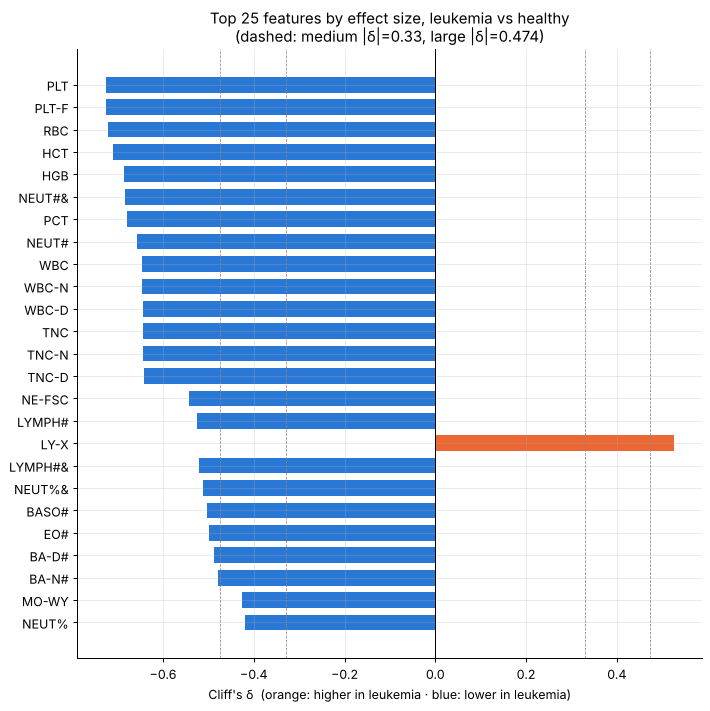

In [29]:
t = cmp_.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(t.feature, t.cliffs_delta, color=[C_LK if v > 0 else C_HC for v in t.cliffs_delta], height=0.7)
for x in (-0.474, -0.33, 0.33, 0.474): ax.axvline(x, color="#888780", lw=0.6, ls="--")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cliff's δ  (orange: higher in leukemia · blue: lower in leukemia)")
ax.set_title("Top 25 features by effect size, leukemia vs healthy\n(dashed: medium |δ|=0.33, large |δ|=0.474)")
plt.tight_layout(); savefig("A10_effect_sizes_top25"); plt.show()

In [30]:
# Literature markers named in the proposal: where do they rank?
lit = ["WBC", "LYMPH%", "LYMPH#", "HGB", "PLT", "NEUT%", "NEUT#", "MONO#", "RBC", "IG#", "NRBC#", "RDW-CV"]
lit_tab = cmp_[cmp_.feature.isin(lit)][["feature", "median_healthy", "median_leukemia", "cliffs_delta", "effect"]].copy()
lit_tab.insert(1, "rank_of_71", lit_tab.index + 1)
lit_tab.round(3)

,feature,rank_of_71,median_healthy,median_leukemia,cliffs_delta,effect
0,PLT,1,208.00,38.000,-0.726,large
2,RBC,3,3.85,2.560,-0.721,large
4,HGB,5,115.00,79.000,-0.686,large
7,NEUT#,8,5.01,1.050,-0.657,large
8,WBC,9,7.28,1.945,-0.646,large
15,LYMPH#,16,1.23,0.450,-0.526,large
24,NEUT%,25,72.20,51.600,-0.418,medium
26,RDW-CV,27,13.30,15.200,0.402,medium
27,MONO#,28,0.48,0.170,-0.375,medium
36,LYMPH%,37,17.80,27.500,0.266,small


**Reading (A10).**
* **23 of 71 features have a large effect.** The strongest are **PLT ↓ (δ = −0.73), RBC ↓, HCT ↓, HGB ↓**, i.e. thrombocytopenia and anaemia from marrow failure, then **neutrophil count ↓ and total WBC ↓** (median 1.9 vs 7.3).
  The redundant WBC channels (WBC-N, WBC-D, TNC…) repeat the same signal. Cell-population parameters (NE-FSC ↓, LY-X ↑) are next: the analyser "sees" abnormal cells.
* **Literature markers from the proposal** all differ in the expected direction: PLT (rank 1), HGB (5), WBC (9), LYMPH# ↓ (16), NEUT% ↓ (25), RDW-CV ↑ (27), and **LYMPH% ↑** (37, relative lymphocytosis). This is a useful univariate reference for checking the SHAP ranking in RQ2.
  IG# is negligible, even though immature granulocytes are often mentioned.
* **WBC is lower *on average* but abnormal in both directions** (long high tail). A single linear WBC term in LR can only push risk one way, so LR will under-use the high-WBC cases.
  Log-transforming helps, and ratio features (Part C) may help further. This is a known weakness of LR compared with trees, worth showing in the error analysis.
* **Missingness differs strongly by class**: platelet indices are missing in 28.7% of leukemia vs 5.7% of healthy records, and the differential in 5.6% vs 0.2%. Missing-indicators carry signal, so they go into the pipeline (a recorded modelling decision).

## A11. Between-hospital shift (healthy patients only, development sites)
RQ1 asks whether a model transfers to an unseen hospital. If healthy reference values already differ between sites, part of the challenge is **site shift**. Only the training sites are inspected here.

In [31]:
shift = dev[dev.y == 0].groupby("site", observed=True)[KEY_FEATURES].median().T.round(2)
shift["max/min ratio"] = (shift.max(axis=1) / shift.min(axis=1).replace(0, np.nan)).round(2)
display(shift)
miss_site = dev.groupby("site", observed=True)[["MPV", "NEUT%", "NE-SSC", "LY-X"]].apply(lambda g: g.isna().mean() * 100).round(1)
print("Missing % by training site (recording practice differs):"); display(miss_site)

site,A,B,C,max/min ratio
WBC,7.31,7.51,7.18,1.05
NEUT#,5.28,4.81,4.87,1.10
LYMPH#,1.03,1.59,1.32,1.54
MONO#,0.54,0.56,0.40,1.40
NEUT%,75.10,66.70,71.30,1.13
LYMPH%,14.70,22.20,19.70,1.51
MONO%,7.60,7.60,5.70,1.33
HGB,115.00,123.00,112.00,1.10
RBC,3.79,4.23,3.80,1.12
HCT,34.90,37.40,34.90,1.07


Missing % by training site (recording practice differs):


,MPV,NEUT%,NE-SSC,LY-X
site,,,,
A,14.2,2.1,2.3,0.1
B,15.3,2.5,2.5,0.0
C,11.9,1.8,1.9,0.2


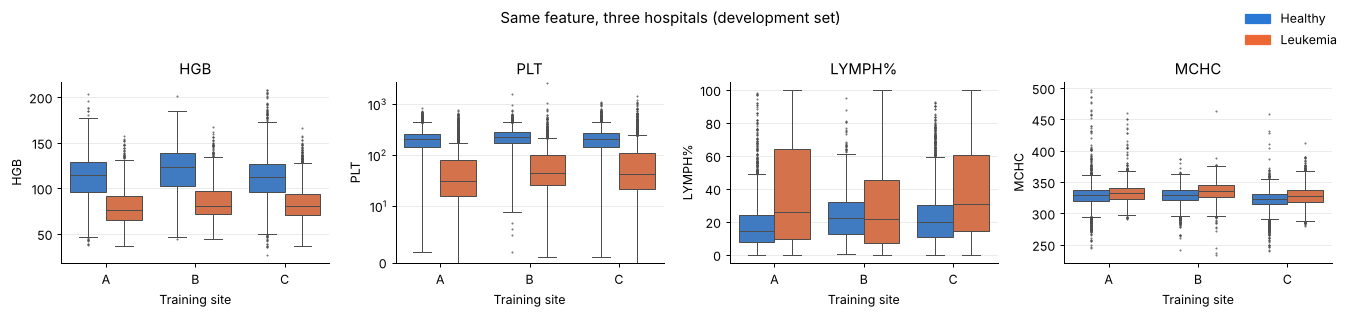

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, f in zip(axes, ["HGB", "PLT", "LYMPH%", "MCHC"]):
    s = dev[[f, "y", "site"]].dropna().copy(); s["cls"] = s.y.map(LAB); s["site"] = s["site"].astype(str)
    sns.boxplot(data=s, x="site", y=f, hue="cls", order=["A", "B", "C"], hue_order=["Healthy", "Leukemia"],
                palette={"Healthy": C_HC, "Leukemia": C_LK}, fliersize=0.5, linewidth=0.8, ax=ax)
    if f == "PLT": ax.set_yscale("symlog", linthresh=10); ax.set_ylim(bottom=0)
    ax.set_title(f); ax.set_xlabel("Training site"); ax.legend_.remove() if ax.legend_ else None
h = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (C_HC, C_LK)]
fig.legend(h, ["Healthy", "Leukemia"], loc="upper right", frameon=False)
fig.suptitle("Same feature, three hospitals (development set)", y=1.02)
plt.tight_layout(); savefig("A11_site_shift"); plt.show()

**Reading (A11).** Even within the three training hospitals, the **healthy control groups differ**. Site A's controls have lower lymphocytes (LYMPH% median 14.7 vs 22.2 at B) and lower HGB (115 vs 123 g/L), suggesting a sicker, more inpatient-like control population.
Recording practice differs too: platelet indices are missing for 12–15% of training records but only 4–9% at the validation hospitals (table B).
So a model trained here meets **both a different case mix and a different missingness pattern** at an unseen hospital. This is exactly what the external-hospital evaluation for RQ1 is designed to expose.

## Summary of Parts A & B

**Data**: 446,663 raw CBC records from 7 hospitals in 11 files; 74 numeric columns + id + label. After fixed cleaning: **446,637 records, 71 features**.

| # | Finding | Consequence / decision |
|---|---|---|
| 1 | Training files are down-sampled to 1:2 (33% leukemia); validation/test hospitals have 1.8–5% (G: 18.6%) | Report prevalence with every precision/PR-AUC; class weighting or SMOTE in training folds only |
| 2 | No explicit NaN, but **~105k pre-filled per-file means** (disguised missing) | R3: restored to NaN; imputation learned inside folds |
| 3 | Missing values also coded as **0** in blocks (differential, platelet indices, cell-population) | R5–R8: zeros → NaN |
| 4 | Missingness is **informative** (no differential: 31% leukemia) and **site-specific** | Use imputation + missing-indicators in the pipeline; monitor site shortcut |
| 5 | **HCT stored as fraction at sites B, C** | R4: converted to % |
| 6 | 139 impossible MCHC > 500 g/L; 15 zero RBC panels | R5, R9: set to NaN (records kept) |
| 7 | 22 duplicate/conflicting records (valid D, G); no cross-split duplicates; no patient ID | R10: removed; patient grouping limitation stated |
| 8 | 3 blast-suspicion flags: mostly missing, absent at several sites, label shortcut | R2: dropped (matches the paper's feature list) |
| 9 | Counts are heavily right-skewed; extremes are mostly leukemia | No outlier removal; log-transform in the LR pipeline |
| 10 | Strong multicollinearity (many |ρ| ≥ 0.95 pairs) | Regularised LR; interpret odds ratios on a de-duplicated subset |
| 11 | Largest effects: PLT ↓, RBC/HCT/HGB ↓, NEUT# and WBC ↓, cell-population shifts; LYMPH% ↑, RDW ↑. WBC is abnormal in both directions | Consistent with literature (RQ2 reference); log-transform + ratio features (Part C) |
| 12 | Healthy reference values and recording habits differ between hospitals | External-hospital evaluation is essential for RQ1 |